# Cable-actuated Hoberman ring

Step by step. One `Model` holds the parameters, the cables, the current deployment `t` and the
selected link; every cell below is a view on it. Sliders are shared widgets, so the `t` slider shown
in several cells is the same slider and moving it anywhere updates all views.

Errors inside callbacks are printed in the small log box under each view.

In [1]:
import numpy as np
from collections import defaultdict
from importlib import reload
from plicata import hoberman as H, views
reload(H); reload(views)

p = H.Params(
    n=20, arm_len=53.8, link_width=10.0, hole_dia=3.0,
    pin_dia=3.0,        # bearing diameter the cable runs over
    cable_dia=0.5, clearance=0.5,
    t_min=0.10, t_max=0.90,
)
# Unit numbers run CLOCKWISE (hoberman.NUM_DIR).
# expansion  starts at link 0  and walks FORWARDS   0 -> 5    (green links)
# contraction starts at link 17 and walks BACKWARDS 17 -> 11  (blue links)
exp = H.expansion_cable(k0=0, n_units=6)
con = H.contraction_cable(k0=17, n_units=6)

m = views.Model(p, [con, exp], fam=1, unit=2)   # unit 2 = a green (expand) link

d = np.degrees
print(f"n = {p.n} units   half-sector alpha = {d(p.alpha):.2f} deg   "
      f"apex (kink) angle = {d(p.apex):.2f} deg   kappa = {d(p.kappa):.2f} deg")
print(f"arm A = {p.arm_len:.2f} mm   chord Ja-Jb = {p.chord:.2f} mm")
for _t in (p.t_min, 0.5, p.t_max):
    _rho, _ri, _ro = H.state_radii(p, _t)
    print(f"  t={_t:.2f}:  rho={_rho:8.2f}  r_in={_ri:8.2f}  r_out={_ro:8.2f}  outer dia={2*_ro:8.2f}")

roles = H.link_roles(p, m.cables)
by = defaultdict(list)
for k in range(p.n):
    by[roles[(1, k)]].append(k)
print(f"\nlink types -- family 0: plain (yellow), all {p.n} links")
print("family 1, clockwise:")
for r in ("anchor", "expand", "contract", "idle", "both"):
    if by[r]:
        print(f"  {r:9s} {by[r]}")

n = 20 units   half-sector alpha = 9.00 deg   apex (kink) angle = 162.00 deg   kappa = 81.00 deg
arm A = 53.80 mm   chord Ja-Jb = 106.28 mm
  t=0.10:  rho=  101.12  r_in=   48.46  r_out=  151.30  outer dia=  302.60
  t=0.50:  rho=  261.51  r_in=  223.35  r_out=  293.23  outer dia=  586.47
  t=0.90:  rho=  340.48  r_in=  328.71  r_out=  343.87  outer dia=  687.74

link types -- family 0: plain (yellow), all 20 links
family 1, clockwise:
  anchor    [0, 17]
  expand    [1, 2, 3, 4, 5]
  contract  [11, 12, 13, 14, 15, 16]
  idle      [6, 7, 8, 9, 10, 18, 19]


## 1. Structure

Drag on the ring to change `t`, or use the slider. Unit numbers are printed at the kink pivot
and run **clockwise**.

Three link bodies get built, distinguished by the channel milled into them:

| colour | type | what it is |
|---|---|---|
| yellow | type 1 | family 0, no cable |
| green | type 2 | family 1, carries the **expansion** cable (anchored at link 0, forwards) |
| blue | type 3 | family 1, carries the **contraction** cable (anchored at link 17, backwards) |
| red | — | the link each cable is anchored to, one per cable |
| grey | — | family 1 link that no cable reaches yet |

The colours come from `hoberman.link_roles()`, which reads the cables themselves, so the
picture cannot drift out of step with the routing. The link the next cells focus on is drawn
with a heavy dark outline rather than recoloured, so it still shows its own type.

In [2]:
ring = views.RingView(m)
ring

## 2. One link held fixed

The selected link stays put (kink at origin, apex bisector along +x); the neighbouring scissor units
and the cables move around it. Tick *cable trails* to overlay the cable path for the whole `t` range,
which is the raw channel before offsetting.

In [3]:
link = views.LinkView(m, n_units_shown=1)
link

## 3. Channel envelope

The trails from step 2, each buffered by cable radius plus clearance and unioned (shapely).
This is the pocket outline for this link.

Only the **green** and **blue** links have a channel, so the view draws just the cables that
actually run through the selected link. Select a yellow (family 0) or grey link and it says
there is nothing to mill.

In [4]:
env = views.EnvelopeView(m)
env

## 4. Cable lengths and motor relation

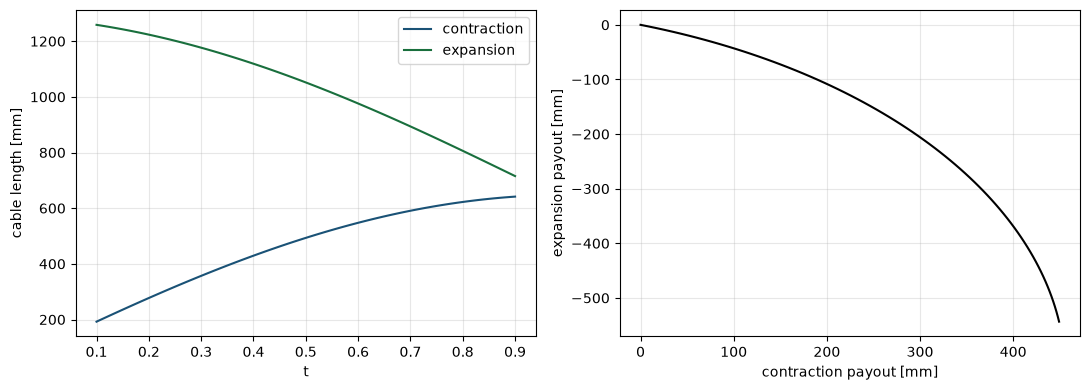

In [5]:
import matplotlib.pyplot as plt
ts = np.linspace(m.p.t_min, m.p.t_max, 80)
Lc, Le = H.length_curve(m.p, con, ts), H.length_curve(m.p, exp, ts)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ts, Lc, c=con.color, label="contraction"); ax[0].plot(ts, Le, c=exp.color, label="expansion")
ax[0].set_xlabel("t"); ax[0].set_ylabel("cable length [mm]"); ax[0].legend()
ax[1].plot(Lc - Lc[0], Le - Le[0], "k"); ax[1].set_xlabel("contraction payout [mm]"); ax[1].set_ylabel("expansion payout [mm]")
for a in ax: a.grid(alpha=.3)
plt.tight_layout()

## 5. Two programmable servos

Round winch drums, rates programmed from a lookup table. Per cable: payout from `t_min`, drum angle for a
given drum radius, and the transmission ratio in mm of cable per mm of kink radius rho (the torque-for-speed
trade of the weave). The follower table maps contraction servo angle to expansion servo angle; if gravity
handles contraction, only the expansion column matters.

drums: contraction r=10.0 mm, expansion r=10.0 mm
stroke: rho 101.1 -> 340.5 mm, r_out 151.3 -> 343.9 mm
contraction servo: 449.3 mm, 7.15 turns
expansion servo:   543.4 mm, 8.65 turns
transmission (mm cable / mm rho): contraction 1.88..1.88, expansion 0.64..12.80
servo speed ratio exp/con: 0.34..6.82


'servo_table.json'

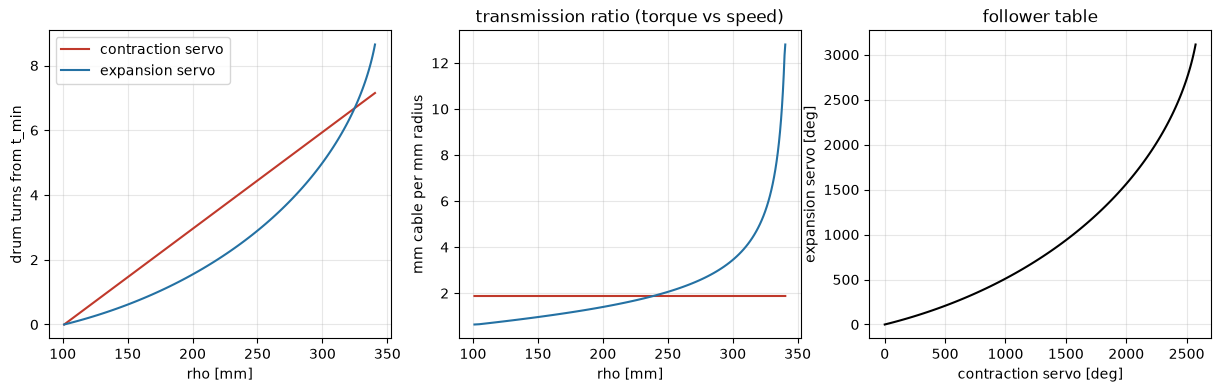

In [6]:
from plicata import actuation
reload(actuation)
tab = actuation.table(m.p, con, exp, r_drum_con=7.5, r_drum_exp=7.5)
print(actuation.summary(tab))
actuation.plot(tab);
actuation.export_csv("servo_table.csv", tab)
actuation.export_json("servo_table.json", tab)

## 6. Export DXF

In [7]:
# Two drawings.
# 1. the ring in several deployment states, with the cable paths, all on one origin.
H.export_ring_dxf("drawings/hoberman_ring_states.dxf", m.p, m.cables,
                  ts_states=[m.p.t_min, 0.5, m.p.t_max])

# 2. the part sheet: one link body at the origin, inner arm straight down, with the
#    cable drawn from the previous link to the next one at every `step` of deployment.
#    No boolean -- raw paths, one layer per cable colour, so both parts trace off it.
H.export_link_dxf("drawings/hoberman_link_part.dxf", m.p, m.cables, step=0.1)
print("states drawn:", H.state_steps(m.p, 0.1))
print("cable traced on link:", {c.role: H.representative_link(m.p, c)[1] for c in m.cables if c.role})

states drawn: (0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9)
cable traced on link: {'contract': 14, 'expand': 3}
